# Tugas Individu: Studi Kasus Klasifikasi
## Prediksi Gagal Bayar Kartu Kredit (*Credit Card Default Prediction*) dengan Machine Learning

**Nama:** Muhammad Faeruz Wafi Abidin  
**Program Studi:** D3 Statistika Terapan dan Komputasi, Universitas Negeri Semarang  
**Mata Kuliah:** *(isi nama mata kuliah)*  

---
**Daftar isi**
1. Permasalahan
2. Metode klasifikasi
3. Dataset
4. Tahapan penerapan (EDA, preprocessing, pemodelan, evaluasi)
5. Hasil dan pembahasan
6. Manfaat
7. Kesimpulan
8. Referensi

## 1. Permasalahan

Bank penerbit kartu kredit menghadapi risiko **gagal bayar (*default*)**, yaitu kondisi ketika nasabah tidak mampu membayar tagihan pada bulan berikutnya. Gagal bayar menyebabkan kerugian finansial dan memengaruhi kualitas portofolio kredit. Di sisi lain, jika bank terlalu ketat menolak nasabah, peluang pendapatan dari bunga dan biaya layanan ikut hilang.

Kasus ini dirujuk dari penelitian Yeh & Lien (2009) pada data nasabah kartu kredit di Taiwan. Pada periode tersebut, penerbitan kartu yang agresif membuat banyak nasabah memiliki utang melebihi kemampuan bayar, sehingga bank membutuhkan alat untuk menilai risiko nasabah secara objektif.

**Rumusan masalah:** apakah seorang nasabah akan **gagal bayar pada bulan berikutnya** (kelas 1) atau **tidak** (kelas 0), berdasarkan profil demografi, riwayat pembayaran, jumlah tagihan, dan jumlah pembayaran selama 6 bulan terakhir?

Ini adalah masalah **klasifikasi biner** dengan kelas yang **tidak seimbang** (nasabah gagal bayar adalah minoritas).

## 2. Metode Klasifikasi

Tiga model dibandingkan, dari yang sederhana ke yang lebih kompleks:

| Model | Alasan dipilih |
|---|---|
| **Logistic Regression** | *Baseline*; mudah diinterpretasi dan lazim dipakai pada *credit scoring*. |
| **Random Forest** (Breiman, 2001) | Kumpulan pohon keputusan (*bagging*); menangkap hubungan non-linear dan tahan terhadap *overfitting*. |
| **Gradient Boosting** | Pohon dibangun berurutan, tiap pohon memperbaiki kesalahan sebelumnya; biasanya akurat pada data tabular. |

Karena kelas tidak seimbang, **akurasi saja tidak memadai**. Evaluasi memakai *precision*, *recall*, *F1-score*, dan **ROC-AUC**. Untuk Logistic Regression dan Random Forest dipakai `class_weight="balanced"` agar kelas minoritas tidak diabaikan.

## 3. Dataset

**Default of Credit Card Clients** (UCI Machine Learning Repository), 30.000 nasabah kartu kredit di Taiwan, April sampai September 2005. Sumber: Yeh & Lien (2009).

| Kelompok | Variabel | Keterangan |
|---|---|---|
| Kredit | `LIMIT_BAL` | Batas kredit (NT$) |
| Demografi | `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | Jenis kelamin, pendidikan, status pernikahan, usia |
| Riwayat bayar | `PAY_1` ... `PAY_6` | Status pembayaran bulan September sampai April (-1 = lunas tepat waktu, 1 = telat 1 bulan, dst.) |
| Tagihan | `BILL_AMT1` ... `BILL_AMT6` | Jumlah tagihan tiap bulan |
| Pembayaran | `PAY_AMT1` ... `PAY_AMT6` | Jumlah yang dibayar tiap bulan |
| **Target** | `DEFAULT` | 1 = gagal bayar bulan berikutnya, 0 = tidak |

Dataset: https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients

## 4. Tahapan Penerapan

### 4.1 Impor library dan memuat data

In [1]:
!pip install -q ucimlrepo xlrd

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             accuracy_score, precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [3]:
NAMES = (["LIMIT_BAL","SEX","EDUCATION","MARRIAGE","AGE"]
         + [f"PAY_{i}" for i in range(1,7)]
         + [f"BILL_AMT{i}" for i in range(1,7)]
         + [f"PAY_AMT{i}" for i in range(1,7)])

# Muat dataset. Urutan percobaan: UCI -> OpenML -> file .xls dari repositori GitHub.
def muat_data():
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=350)
        return ds.data.features.copy(), ds.data.targets.iloc[:, 0].copy()
    except Exception as e:
        print("UCI gagal:", type(e).__name__)
    try:
        from sklearn.datasets import fetch_openml
        ds = fetch_openml(data_id=42477, as_frame=True)
        return ds.data.copy(), ds.target.copy()
    except Exception as e:
        print("OpenML gagal:", type(e).__name__)
    import os
    sumber = ("default of credit card clients.xls" if os.path.exists("default of credit card clients.xls")
              else "https://raw.githubusercontent.com/wafii237/Prediksi-Gagal-Bayar-Kartu-Kredit-dengan-Machine-Learning/main/default%20of%20credit%20card%20clients.xls")
    raw = pd.read_excel(sumber, header=1)          # baris pertama berisi judul, header ada di baris kedua
    print("Data dimuat dari file .xls")
    return raw.iloc[:, 1:24].copy(), raw.iloc[:, 24].copy()   # buang kolom ID; kolom terakhir = target

X, y = muat_data()
X.columns = NAMES            # kolom diurutkan sesuai dokumentasi dataset
y = y.astype(int).rename("DEFAULT")
df = pd.concat([X, y], axis=1)
print(df.shape)
df.head()

Data dimuat dari file .xls
(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 4.2 Eksplorasi data (EDA)

In [4]:
df.info()
print("\nMissing value per kolom:", df.isna().sum().sum())
print("Baris duplikat:", df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_1      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   30000 non-nu

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


DEFAULT
0    23364
1     6636
Name: count, dtype: int64 
Proporsi gagal bayar: 22.12%


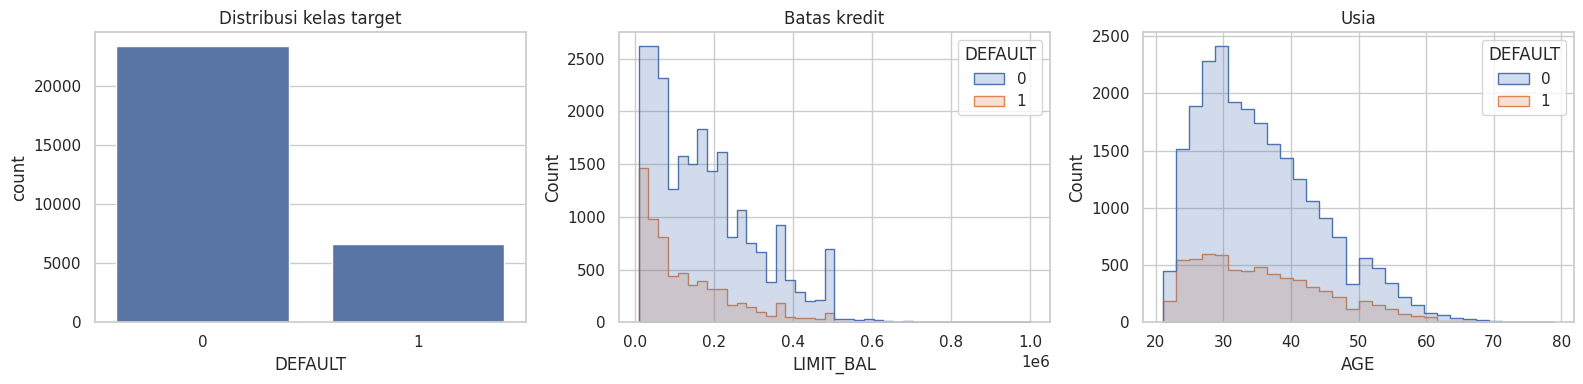

In [5]:
# Distribusi target
counts = df["DEFAULT"].value_counts().sort_index()
print(counts, "\nProporsi gagal bayar: {:.2%}".format(df["DEFAULT"].mean()))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x="DEFAULT", data=df, ax=ax[0]); ax[0].set_title("Distribusi kelas target")
sns.histplot(data=df, x="LIMIT_BAL", hue="DEFAULT", bins=40, element="step", ax=ax[1]); ax[1].set_title("Batas kredit")
sns.histplot(data=df, x="AGE", hue="DEFAULT", bins=30, element="step", ax=ax[2]); ax[2].set_title("Usia")
plt.tight_layout(); plt.show()

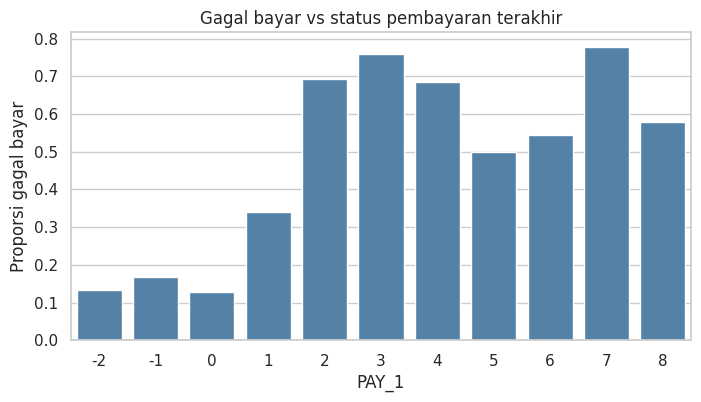

,PAY_1,mean,count
0,-2,0.132294,2759
1,-1,0.167781,5686
2,0,0.128113,14737
3,1,0.339479,3688
4,2,0.691414,2667
5,3,0.757764,322
6,4,0.684211,76
7,5,0.500000,26
8,6,0.545455,11
9,7,0.777778,9


In [6]:
# Tingkat gagal bayar menurut status pembayaran bulan terakhir (PAY_1)
rate = df.groupby("PAY_1")["DEFAULT"].agg(["mean", "count"]).reset_index()
plt.figure(figsize=(8,4))
sns.barplot(data=rate, x="PAY_1", y="mean", color="steelblue")
plt.ylabel("Proporsi gagal bayar"); plt.title("Gagal bayar vs status pembayaran terakhir")
plt.show()
rate

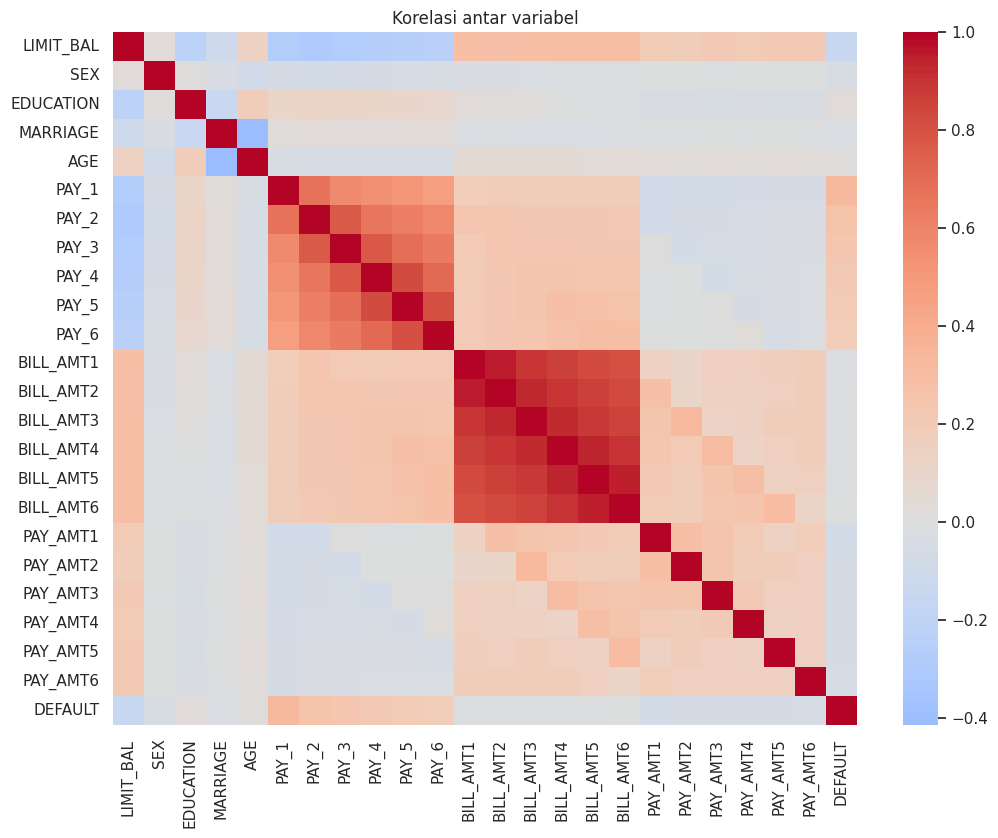

PAY_1        0.324794
PAY_2        0.263551
PAY_3        0.235253
PAY_4        0.216614
PAY_5        0.204149
PAY_6        0.186866
EDUCATION    0.028006
AGE          0.013890
Name: DEFAULT, dtype: float64


In [7]:
plt.figure(figsize=(12,9))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Korelasi antar variabel"); plt.show()
print(df.corr()["DEFAULT"].drop("DEFAULT").sort_values(ascending=False).head(8))

### 4.3 Preprocessing

- Dokumentasi dataset hanya mendefinisikan `EDUCATION` 1 sampai 4 dan `MARRIAGE` 1 sampai 3, tetapi data memuat kode lain (0, 5, 6). Kode ini digabung ke kategori "lainnya".
- Data dibagi 80% latih dan 20% uji dengan **stratifikasi** agar proporsi kelas terjaga.
- Standardisasi fitur hanya dipakai untuk Logistic Regression. Model berbasis pohon tidak membutuhkannya.
- *Scaler* dipasang hanya pada data latih (di dalam `Pipeline`) untuk mencegah **kebocoran data**.

In [8]:
print("EDUCATION sebelum:", sorted(df["EDUCATION"].unique()))
print("MARRIAGE sebelum:", sorted(df["MARRIAGE"].unique()))

df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

print("EDUCATION sesudah:", sorted(df["EDUCATION"].unique()))
print("MARRIAGE sesudah:", sorted(df["MARRIAGE"].unique()))

EDUCATION sebelum: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
MARRIAGE sebelum: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
EDUCATION sesudah: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
MARRIAGE sesudah: [np.int64(1), np.int64(2), np.int64(3)]


In [9]:
X = df.drop(columns="DEFAULT")
y = df["DEFAULT"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Latih:", X_train.shape, "| Uji:", X_test.shape)
print("Proporsi gagal bayar latih: {:.3f} | uji: {:.3f}".format(y_train.mean(), y_test.mean()))

Latih: (24000, 23) | Uji: (6000, 23)
Proporsi gagal bayar latih: 0.221 | uji: 0.221


### 4.4 Pemodelan dan validasi silang

In [10]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    cv_rows.append({"Model": name, "ROC-AUC (CV)": auc.mean(), "Std AUC": auc.std(), "F1 (CV)": f1.mean()})

pd.DataFrame(cv_rows).round(4)

,Model,ROC-AUC (CV),Std AUC,F1 (CV)
0,Logistic Regression,0.7264,0.0106,0.4804
1,Random Forest,0.7800,0.0039,0.5428
2,Gradient Boosting,0.7829,0.0060,0.4770


### 4.5 Evaluasi pada data uji

In [11]:
rows, fitted, probas = [], {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    fitted[name], probas[name] = model, prob
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.6795,0.3671,0.6202,0.4612,0.7084
Random Forest,0.7988,0.5482,0.5147,0.5309,0.7702
Gradient Boosting,0.8185,0.6617,0.3670,0.4721,0.7785


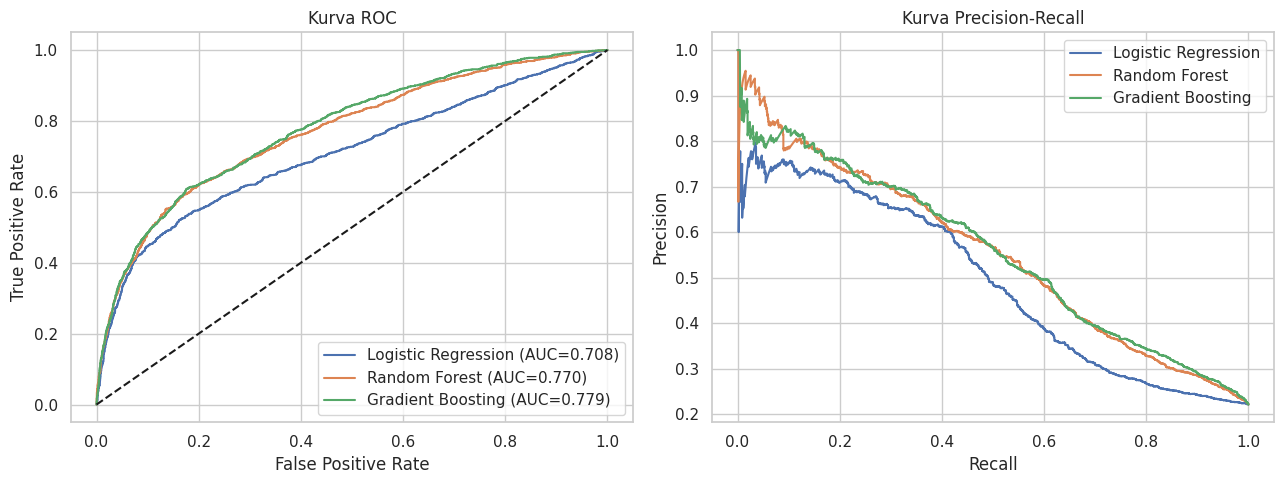

In [12]:
# Kurva ROC dan Precision-Recall
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, prob in probas.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
    p, r, _ = precision_recall_curve(y_test, prob)
    ax[1].plot(r, p, label=name)
ax[0].plot([0,1],[0,1],"k--"); ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate"); ax[0].set_title("Kurva ROC"); ax[0].legend()
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Kurva Precision-Recall"); ax[1].legend()
plt.tight_layout(); plt.show()

Model terbaik: Gradient Boosting
                   precision    recall  f1-score   support

Tidak gagal bayar       0.84      0.95      0.89      4673
      Gagal bayar       0.66      0.37      0.47      1327

         accuracy                           0.82      6000
        macro avg       0.75      0.66      0.68      6000
     weighted avg       0.80      0.82      0.80      6000



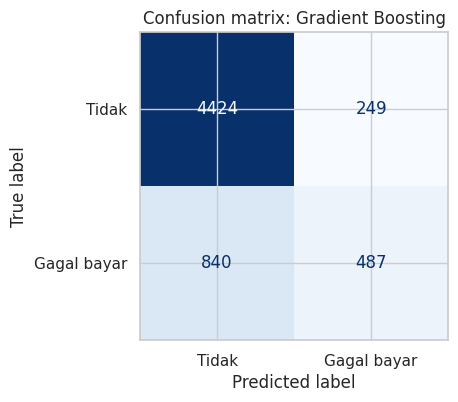

In [13]:
# Model terbaik berdasarkan ROC-AUC data uji
best_name = results["ROC-AUC"].idxmax()
print("Model terbaik:", best_name)

pred_best = (probas[best_name] >= 0.5).astype(int)
print(classification_report(y_test, pred_best, target_names=["Tidak gagal bayar", "Gagal bayar"]))

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_best),
                       display_labels=["Tidak", "Gagal bayar"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix: {best_name}"); plt.show()

### 4.6 Penyesuaian ambang batas (*threshold*)

Ambang 0,5 belum tentu optimal. Bagi bank, **gagal mendeteksi nasabah berisiko (*false negative*)** biasanya lebih mahal daripada salah menandai nasabah baik. Berikut dampak perubahan ambang terhadap *precision* dan *recall* pada model terbaik.

In [14]:
prob = probas[best_name]
thr_rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pr = (prob >= t).astype(int)
    thr_rows.append({"Threshold": t,
                     "Precision": precision_score(y_test, pr),
                     "Recall": recall_score(y_test, pr),
                     "F1": f1_score(y_test, pr)})
pd.DataFrame(thr_rows).round(4)

,Threshold,Precision,Recall,F1
0,0.2,0.4251,0.6564,0.5160
1,0.3,0.5326,0.5298,0.5312
2,0.4,0.6187,0.4378,0.5128
3,0.5,0.6617,0.3670,0.4721
4,0.6,0.6991,0.3082,0.4278


### 4.7 Faktor yang paling berpengaruh (*permutation importance*)

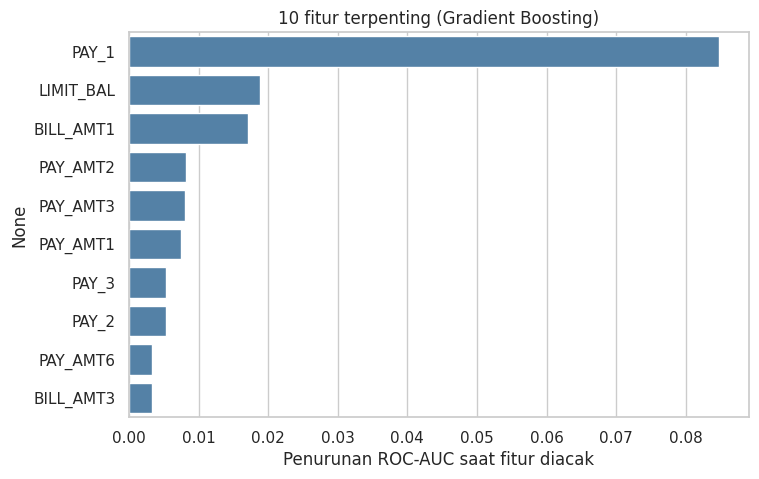

PAY_1        0.0849
LIMIT_BAL    0.0188
BILL_AMT1    0.0171
PAY_AMT2     0.0082
PAY_AMT3     0.0080
PAY_AMT1     0.0075
PAY_3        0.0053
PAY_2        0.0053
PAY_AMT6     0.0033
BILL_AMT3    0.0032
dtype: float64

In [15]:
perm = permutation_importance(fitted[best_name], X_test, y_test,
                              scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8,5))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.xlabel("Penurunan ROC-AUC saat fitur diacak"); plt.title(f"10 fitur terpenting ({best_name})")
plt.show()
imp.round(4)

## 5. Hasil dan Pembahasan

> Hasil di bawah diperoleh dari eksekusi notebook ini dengan `random_state=42`. Jika dijalankan ulang, angka bisa berbeda sangat tipis tergantung versi library.

**Gambaran data.** Dari 30.000 nasabah, **22,12%** (6.636 nasabah) gagal bayar. Model yang selalu menebak "tidak gagal bayar" sudah mencapai akurasi sekitar 77,9%, sehingga akurasi bukan ukuran yang memadai. Variabel dengan korelasi terkuat terhadap target adalah status pembayaran (`PAY_1` sebesar 0,32; `PAY_2` 0,26). Nasabah dengan keterlambatan 2 bulan pada status terakhir (`PAY_1` = 2) memiliki proporsi gagal bayar sekitar **69%**, jauh di atas nasabah yang membayar tepat waktu atau memakai kredit berputar (sekitar 13% sampai 17%).

**Perbandingan model (data uji, ambang 0,5).**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0,6795 | 0,3671 | 0,6202 | 0,4612 | 0,7084 |
| Random Forest | 0,7988 | 0,5482 | 0,5147 | 0,5309 | 0,7702 |
| **Gradient Boosting** | **0,8185** | **0,6617** | 0,3670 | 0,4721 | **0,7785** |

Validasi silang 5-fold memberi urutan ROC-AUC yang sama: Gradient Boosting (0,7829), Random Forest (0,7800), Logistic Regression (0,7264). Dua model berbasis pohon jauh lebih baik daripada *baseline* linear, dan selisih antara Gradient Boosting dan Random Forest kecil (sekitar 0,008 pada data uji), sehingga keduanya layak dipertimbangkan.

**Kinerja pada kelas gagal bayar.** Gradient Boosting dipilih sebagai model terbaik berdasarkan ROC-AUC, tetapi pada ambang 0,5 *recall*-nya hanya **36,7%**: dari 1.327 nasabah gagal bayar di data uji, kurang dari 4 dari 10 berhasil terdeteksi, meskipun ketika model menandai seseorang berisiko, tebakannya benar 66,2% (precision). Logistic Regression dan Random Forest memakai `class_weight="balanced"` sehingga *recall*-nya lebih tinggi, dengan *precision* yang lebih rendah. Random Forest memberikan F1 tertinggi pada ambang 0,5 (0,5309).

**Penyesuaian ambang.** Pada Gradient Boosting, menurunkan ambang dari 0,5 ke 0,3 menaikkan *recall* dari 36,7% menjadi 53,0% dan F1 dari 0,4721 menjadi 0,5312, dengan *precision* turun dari 66,2% menjadi 53,3%. Ambang 0,2 menghasilkan *recall* 65,6% tetapi *precision* hanya 42,5%. Pemilihan ambang sebaiknya mengikuti perbandingan biaya antara kerugian akibat gagal bayar yang tidak terdeteksi dan biaya menindaklanjuti nasabah yang sebenarnya aman.

**Faktor penentu.** Berdasarkan *permutation importance*, `PAY_1` (status pembayaran bulan terakhir) paling berpengaruh dengan penurunan ROC-AUC sebesar 0,085 saat diacak, jauh di atas `LIMIT_BAL` (0,019) dan `BILL_AMT1` (0,017). Artinya riwayat keterlambatan terbaru adalah sinyal terkuat risiko gagal bayar, sedangkan variabel demografi hampir tidak muncul di sepuluh besar.

**Keterbatasan.**
- Data berasal dari satu bank di Taiwan tahun 2005, sehingga belum tentu mewakili kondisi lain.
- Terdapat 35 baris dengan nilai identik pada seluruh kolom; baris ini tidak dihapus karena bisa jadi nasabah berbeda dengan profil sama.
- *Hyperparameter* belum dioptimasi menyeluruh (misalnya dengan `GridSearchCV`), dan kinerja model masih moderat (ROC-AUC sekitar 0,78).
- Hasil menunjukkan asosiasi prediktif, bukan hubungan sebab-akibat.
- Variabel demografi seperti jenis kelamin perlu dipertimbangkan dari sisi etika dan regulasi jika dipakai dalam keputusan kredit nyata.

## 6. Manfaat

1. **Manajemen risiko kredit.** Bank dapat mengidentifikasi nasabah berisiko tinggi lebih awal dan mengambil tindakan pencegahan, misalnya pengingat pembayaran atau restrukturisasi.
2. **Penentuan limit kredit.** Skor risiko membantu bank menetapkan atau menyesuaikan batas kredit berdasarkan profil nasabah.
3. **Efisiensi operasional.** Penilaian otomatis menggantikan sebagian proses manual, dan tim penagihan dapat memprioritaskan nasabah dengan skor risiko tertinggi.
4. **Pengambilan keputusan berbasis data.** Faktor risiko yang teridentifikasi (misalnya riwayat keterlambatan) dapat menjadi dasar kebijakan penerbitan kartu.
5. **Manfaat bagi nasabah.** Nasabah yang berisiko kesulitan bayar dapat dihubungi lebih dini sehingga tidak terjerat tunggakan berkepanjangan.

## 7. Kesimpulan

Masalah prediksi gagal bayar kartu kredit dapat dirumuskan sebagai klasifikasi biner dengan kelas tidak seimbang. Dengan tahapan EDA, preprocessing, pemodelan dengan validasi silang, dan evaluasi memakai metrik yang sesuai (*recall*, F1, ROC-AUC), model Machine Learning mampu membedakan nasabah berisiko dan tidak berisiko secara lebih baik daripada tebakan acak. Pemilihan ambang batas perlu disesuaikan dengan biaya kesalahan di dunia nyata. Untuk penerapan sesungguhnya, model perlu divalidasi pada data yang lebih mutakhir, dipantau secara berkala, dan dikaji dari sisi keadilan serta kepatuhan regulasi.

## 8. Referensi

1. Yeh, I-C., & Lien, C-H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications*, 36(2), 2473-2480. https://doi.org/10.1016/j.eswa.2007.12.020
2. Yeh, I-C. (2016). *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
3. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
4. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
5. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
6. Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, 27(8), 861-874.